In [38]:
# Packages
from pathlib import Path
import pandas as pd
import geopandas as gpd
import requests
import io

# Set paths
data_folder = Path.cwd().parent / 'data' 
nwis_data_file = data_folder / 'NWIS.geojson'

In [ ]:
#Create the NWIS geodataframe, if not present
if not nwis_data_file.exists():

    # Form and send the request
    raw_data = requests.get(
        "https://api.waterdata.usgs.gov/ogcapi/v1/collections/monitoring-locations/items?",
        params={
            'f':'csv',
            'limit':50000,
            'properties':'district_code,basin_code,site_type,altitude,drainage_area',
            #'skipGeometry':'false',
            'offset':'0',
            'state_code':'37'
        }
    ).text

    #Read into a dataframe
    df_nwis = pd.read_csv(io.StringIO(raw_data))

    #Compute geometries
    geometries = gpd.points_from_xy(df_nwis['x'],df_nwis['y'])

    #Create geodataframe
    gdf_nwis = gpd.GeoDataFrame(df_nwis,geometry=geometries, crs='4326')

    #Write to geojson
    gdf_nwis.to_file(nwis_data_file)

In [50]:
# Create the county geodataframe
gdf_counties_all = gpd.read_file('https://www2.census.gov/geo/tiger/GENZ2018/shp/cb_2018_us_county_20m.zip')
gdf_counties = gdf_counties_all.loc[gdf_counties_all['STATEFP']=='37']

In [94]:
# Function to show the points in a selected county
def plot_nwis(county_name = 'Durham'):

    #Get the county polygon
    gdf_county = gdf_counties.loc[gdf_counties['NAME']==county_name]

    #Select NWIS points within the county
    gdf_nwis_county = gdf_nwis.loc[gdf_nwis.intersects(gdf_county['geometry'].union_all())]

    #Create the plot
    the_plot = gdf_county.plot(color='lightgray')
    gdf_nwis_county.plot(markersize=5,color='blue', ax=the_plot)
    the_plot.set_title(county_name)

    return the_plot

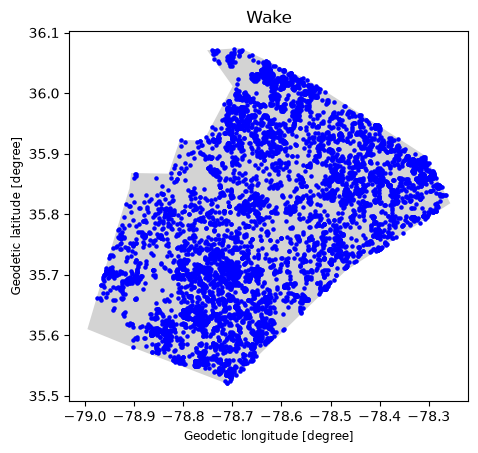

In [96]:
plot_nwis('Wake');